In [1]:

import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    classification_report,
    confusion_matrix
)

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)

# Upload your Amazon dataset in CSV format
uploaded = files.upload()
file_name = next(iter(uploaded))

df = pd.read_csv(file_name, low_memory=False)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())
print("\nColumn names:")
print(df.columns.tolist())

TensorFlow version: 2.21.0


Saving amazon.csv to amazon (1).csv
Dataset loaded successfully!
Dataset shape: (1465, 16)


,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,₹199,"₹1,899",90%,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,₹329,₹699,53%,4.2,"94,363",The boAt Deuce USB 300 2 in 1 cable is compati...,"AEWAZDZZJLQUYVOVGBEUKSLXHQ5A,AG5HTSFRRE6NL3M5S...","Omkar dhale,JD,HEMALATHA,Ajwadh a.,amar singh ...","R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...","Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...",https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,₹154,₹399,61%,4.2,"16,905",[CHARGE & SYNC FUNCTION]- This cable comes wit...,"AE3Q6KSUK5P75D5HFYHCRAOLODSA,AFUGIFH5ZAFXRDSZH...","rahuls6099,Swasat Borah,Ajay Wadke,Pranali,RVK...","R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...



Column names:
['product_id', 'product_name', 'category', 'discounted_price', 'actual_price', 'discount_percentage', 'rating', 'rating_count', 'about_product', 'user_id', 'user_name', 'review_id', 'review_title', 'review_content', 'img_link', 'product_link']


In [2]:
# Normalize column names for easier matching
df.columns = df.columns.str.strip()

def find_column(candidates, required=False):
    # Exact match first
    lookup = {str(c).strip().lower(): c for c in df.columns}

    for name in candidates:
        if name.lower() in lookup:
            return lookup[name.lower()]

    # Match names after removing punctuation/spaces
    normalized = {
        re.sub(r"[^a-z0-9]", "", str(c).lower()): c
        for c in df.columns
    }
    for name in candidates:
        key = re.sub(r"[^a-z0-9]", "", name.lower())
        if key in normalized:
            return normalized[key]

    if required:
        raise ValueError(
            f"Could not find a required column. "
            f"Expected one of {candidates}. "
            f"Available columns: {df.columns.tolist()}"
        )
    return None


review_col = find_column([
    "reviewText", "review_body", "review_content",
    "Text", "review", "content"
], required=True)

rating_col = find_column([
    "overall", "star_rating", "rating",
    "Score", "Rating"
], required=True)

title_col = find_column([
    "product_title", "product_name", "title",
    "ProductName", "product"
])

category_col = find_column([
    "product_category", "category",
    "category_breadcrumbs", "main_category"
])

review_title_col = find_column([
    "review_headline", "review_title", "summary",
    "review_summary", "headline"
])

# Optional numeric product features
numeric_candidates = [
    "price", "discounted_price", "actual_price",
    "discount_percentage"
]
numeric_cols = []
for candidate in numeric_candidates:
    col = find_column([candidate])
    if col is not None and col not in numeric_cols:
        numeric_cols.append(col)

print("Review column:", review_col)
print("Rating column:", rating_col)
print("Product title column:", title_col)
print("Category column:", category_col)
print("Numeric product features:", numeric_cols)

# Create a clean working dataframe
data = pd.DataFrame(index=df.index)

# Combine review headline and review body, if available
body = df[review_col].fillna("").astype(str).str.strip()

if review_title_col is not None and review_title_col != review_col:
    headline = df[review_title_col].fillna("").astype(str).str.strip()
    data["review_text"] = (headline + " " + body).str.strip()
else:
    data["review_text"] = body

# Product text features
data["product_title"] = (
    df[title_col].fillna("unknown product").astype(str)
    if title_col else "unknown product"
)

data["category"] = (
    df[category_col].fillna("unknown").astype(str)
    if category_col else "unknown"
)

# Convert target rating to numeric
data["rating"] = pd.to_numeric(
    df[rating_col].astype(str).str.strip(),
    errors="coerce"
)

# Remove missing text, missing ratings, and invalid ratings
data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna(subset=["rating"])
data = data[data["rating"].between(1, 5)]
data = data[data["rating"].isin([1, 2, 3, 4, 5])]
data = data[data["review_text"].str.strip().ne("")]

# Clean review text without removing sentiment-bearing words
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z0-9'\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

data["review_text"] = data["review_text"].apply(clean_text)
data["product_title"] = (
    data["product_title"].fillna("unknown product").astype(str)
)
data["category"] = (
    data["category"].fillna("unknown").astype(str)
)

# Convert available price/discount fields to numbers
for col in numeric_cols:
    values = (
        df.loc[data.index, col].astype(str)
        .str.replace(",", "", regex=False)
        .str.replace("₹", "", regex=False)
        .str.replace("$", "", regex=False)
        .str.replace("£", "", regex=False)
        .str.replace("%", "", regex=False)
        .str.strip()
    )
    data[col] = pd.to_numeric(values, errors="coerce")

# Keep only rows that survived the text/rating cleaning
data = data.replace([np.inf, -np.inf], np.nan)
data = data.drop_duplicates(
    subset=["review_text", "product_title", "category", "rating"]
).reset_index(drop=True)

print("Clean dataset shape:", data.shape)
print("\nMissing values after cleaning:")
print(data.isnull().sum())
print("\nRating distribution:")
print(data["rating"].value_counts().sort_index())

display(data.head())

Review column: review_content
Rating column: rating
Product title column: product_name
Category column: category
Numeric product features: ['discounted_price', 'actual_price', 'discount_percentage']
Clean dataset shape: (169, 7)

Missing values after cleaning:
review_text            0
product_title          0
category               0
rating                 0
discounted_price       0
actual_price           0
discount_percentage    0
dtype: int64

Rating distribution:
rating
2.0      1
3.0      4
4.0    161
5.0      3
Name: count, dtype: int64


,review_text,product_title,category,rating,discounted_price,actual_price,discount_percentage
0,a good braided cable for your type c device go...,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,4.0,199.0,349,43
1,a good braided cable for your type c device go...,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,4.0,199.0,299,33
2,a good braided cable for your type c device go...,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,4.0,249.0,399,38
3,worked on iphone 7 and didn t work on xr good ...,Flix Micro Usb Cable For Smartphone (Black),Computers&Accessories|Accessories&Peripherals|...,4.0,59.0,199,70
4,ok cable three pin with hybrid wire sturdy nic...,Ambrane Unbreakable 3 in 1 Fast Charging Braid...,Computers&Accessories|Accessories&Peripherals|...,4.0,299.0,399,25


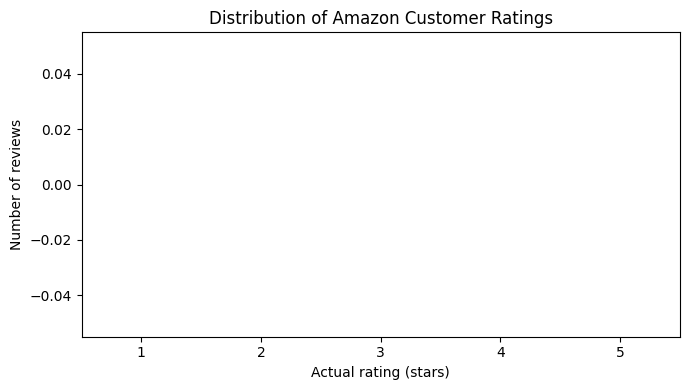

Average review length: 203.41420118343194
Number of usable reviews: 169


In [3]:
plt.figure(figsize=(7, 4))
sns.countplot(
    data=data,
    x="rating",
    hue="rating",
    order=[1, 2, 3, 4, 5],
    palette="viridis",
    legend=False
)
plt.title("Distribution of Amazon Customer Ratings")
plt.xlabel("Actual rating (stars)")
plt.ylabel("Number of reviews")
plt.tight_layout()
plt.show()

print("Average review length:",
      data["review_text"].str.split().str.len().mean())
print("Number of usable reviews:", len(data))

In [5]:
from tensorflow.keras.layers import (
    Input, Embedding, Bidirectional, LSTM, Dense,
    Dropout, Concatenate, GlobalAveragePooling1D
)
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Ensure at least one numeric feature exists
if not numeric_cols:
    data["numeric_placeholder"] = 0.0
    numeric_cols = ["numeric_placeholder"]

# Filter out extremely rare rating classes with fewer than 2 samples to allow stratified split
class_counts = data["rating"].value_counts()
rare_classes = class_counts[class_counts < 2].index
if len(rare_classes) > 0:
    print(f"Removing rare rating classes with fewer than 2 examples: {list(rare_classes)}")
    data = data[~data["rating"].isin(rare_classes)].reset_index(drop=True)

X_train, X_test = train_test_split(
    data,
    test_size=0.20,
    random_state=SEED,
    stratify=data["rating"]
)

# Prepare numeric features: fit imputation and scaling on training only
train_num = X_train[numeric_cols].copy()
test_num = X_test[numeric_cols].copy()

medians = train_num.median().fillna(0)
train_num = train_num.fillna(medians)
test_num = test_num.fillna(medians)

scaler = StandardScaler()
X_train_num = scaler.fit_transform(train_num).astype("float32")
X_test_num = scaler.transform(test_num).astype("float32")

# Encode ratings: 1..5 becomes 0..4
y_train = X_train["rating"].astype(int).to_numpy() - 1
y_test = X_test["rating"].astype(int).to_numpy() - 1

# Review tokenizer and integer sequence encoder
MAX_TOKENS = 20000
REVIEW_LENGTH = 150
TITLE_LENGTH = 30

review_vectorizer = tf.keras.layers.TextVectorization(
    max_tokens=MAX_TOKENS,
    output_mode="int",
    output_sequence_length=REVIEW_LENGTH,
    standardize=None
)

title_vectorizer = tf.keras.layers.TextVectorization(
    max_tokens=10000,
    output_mode="int",
    output_sequence_length=TITLE_LENGTH,
    standardize=None
)

review_vectorizer.adapt(
    tf.data.Dataset.from_tensor_slices(
        X_train["review_text"].astype(str).to_numpy()
    ).batch(256)
)

title_vectorizer.adapt(
    tf.data.Dataset.from_tensor_slices(
        X_train["product_title"].astype(str).to_numpy()
    ).batch(256)
)

category_lookup = tf.keras.layers.StringLookup(
    mask_token=None,
    num_oov_indices=1,
    output_mode="int"
)
category_lookup.adapt(
    tf.data.Dataset.from_tensor_slices(
        X_train["category"].astype(str).to_numpy()
    ).batch(256)
)

# Transform all text and category features
X_train_review = review_vectorizer(
    tf.constant(X_train["review_text"].astype(str).to_numpy())
).numpy()

X_test_review = review_vectorizer(
    tf.constant(X_test["review_text"].astype(str).to_numpy())
).numpy()

X_train_title = title_vectorizer(
    tf.constant(X_train["product_title"].astype(str).to_numpy())
).numpy()

X_test_title = title_vectorizer(
    tf.constant(X_test["product_title"].astype(str).to_numpy())
).numpy()

X_train_category = category_lookup(
    tf.constant(X_train["category"].astype(str).to_numpy())
).numpy()

X_test_category = category_lookup(
    tf.constant(X_test["category"].astype(str).to_numpy())
).numpy()

train_inputs = {
    "review_input": X_train_review,
    "title_input": X_train_title,
    "category_input": X_train_category,
    "numeric_input": X_train_num
}

test_inputs = {
    "review_input": X_test_review,
    "title_input": X_test_title,
    "category_input": X_test_category,
    "numeric_input": X_test_num
}

print("Training examples:", len(X_train))
print("Testing examples:", len(X_test))
print("Review vocabulary size:",
      len(review_vectorizer.get_vocabulary()))
print("Title vocabulary size:",
      len(title_vectorizer.get_vocabulary()))
print("Category vocabulary size:",
      category_lookup.vocabulary_size())

print("\nExample encoded review:")
print(X_train_review[0][:30])

Removing rare rating classes with fewer than 2 examples: [2.0]
Training examples: 134
Testing examples: 34
Review vocabulary size: 3281
Title vocabulary size: 1354
Category vocabulary size: 61

Example encoded review:
[ 66 271 967   9   3  28 142 194   6 117  67   3  18   5  66   2  40  13
  30 312   5 132  39  21  37  13 256   8  11 290]


In [6]:
# Build the Multi-Input Deep Learning Architecture

# 1. Text Branch (Review Content)
review_input = Input(shape=(REVIEW_LENGTH,), name="review_input")
x1 = Embedding(input_dim=MAX_TOKENS, output_dim=128, mask_zero=True)(review_input)
x1 = Bidirectional(LSTM(64, return_sequences=False))(x1)
x1 = Dropout(0.3)(x1)

# 2. Product Title Branch
title_input = Input(shape=(TITLE_LENGTH,), name="title_input")
x2 = Embedding(input_dim=10000, output_dim=64, mask_zero=True)(title_input)
x2 = GlobalAveragePooling1D()(x2)
x2 = Dense(32, activation="relu")(x2)
x2 = Dropout(0.3)(x2)

# 3. Category Branch
category_input = Input(shape=(1,), name="category_input")
x3 = Embedding(input_dim=category_lookup.vocabulary_size() + 1, output_dim=16)(category_input)
x3 = GlobalAveragePooling1D()(x3)

# 4. Numeric Features Branch
numeric_input = Input(shape=(len(numeric_cols),), name="numeric_input")
x4 = Dense(16, activation="relu")(numeric_input)

# Concatenate all processed feature branches
concat = Concatenate()([x1, x2, x3, x4])

# Dense classification layers
decision = Dense(64, activation="relu")(concat)
decision = Dropout(0.3)(decision)

# Output layer for 5 rating classes (representing stars 1..5 mapped to indices 0..4)
output = Dense(5, activation="softmax", name="rating_output")(decision)

model = Model(
    inputs=[review_input, title_input, category_input, numeric_input],
    outputs=output
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# Callbacks for robust training
callbacks = [
    EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5, verbose=1)
]

# Train the model
history = model.fit(
    x=train_inputs,
    y=y_train,
    validation_data=(test_inputs, y_test),
    epochs=30,
    batch_size=16,
    callbacks=callbacks,
    verbose=1
)

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ title_input         │ (None, 30)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ review_input        │ (None, 150)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 30, 64)    │    640,000 │ title_input[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_1         │ (None, 30)        │          0 │ title_input[0][0] │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 150, 128)  │  2,560,000 │ review_input[0][… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 150)       │          0 │ review_input[0][… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ embedding_1[0][0… │
│ (GlobalAveragePool… │                   │            │ not_equal_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ category_input      │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 128)       │     98,816 │ embedding[0][0],  │
│ (Bidirectional)     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 32)        │      2,080 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_2         │ (None, 1, 16)     │        992 │ category_input[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ numeric_input       │ (None, 3)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 32)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 16)        │          0 │ embedding_2[0][0] │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 16)        │         64 │ numeric_input[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 192)       │          0 │ dropout[0][0],    │
│ (Concatenate)       │                   │            │ dropout_1[0][0],  │
│                     │                   │            │ global_average_p… │
│                     │                   │            │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 3,314,629 (12.64 MB)

 Trainable params: 3,314,629 (12.64 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 10s 269ms/step - accuracy: 0.4403 - loss: 1.5702 - val_accuracy: 0.9412 - val_loss: 1.2281 - learning_rate: 0.0010
Epoch 2/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 197ms/step - accuracy: 0.9627 - loss: 0.5458 - val_accuracy: 0.9412 - val_loss: 0.3142 - learning_rate: 0.0010
Epoch 3/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 213ms/step - accuracy: 0.9627 - loss: 0.3131 - val_accuracy: 0.9412 - val_loss: 0.3760 - learning_rate: 0.0010
Epoch 4/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 289ms/step - accuracy: 0.9188 - loss: 0.5614
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 309ms/step - accuracy: 0.9627 - loss: 0.2662 - val_accuracy: 0.9412 - val_loss: 0.3278 - learning_rate: 0.0010
Epoch 5/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 194ms/step - accuracy: 0.9627 - loss: 0.2269 - val_accuracy: 0.9412 - val_loss: 0.3001 - learning_rate: 5.0000e-04
Epoch 6/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 191ms/step - accuracy: 0.9627 - loss: 0.2048 - val_accura

In [7]:

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=1,
    min_lr=1e-6,
    verbose=1
)

history = model.fit(
    train_inputs,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.10,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)


Epoch 1/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 1s/step - accuracy: 0.9583 - loss: 0.2260 - val_accuracy: 1.0000 - val_loss: 0.0250 - learning_rate: 1.2500e-04
Epoch 2/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 2s/step - accuracy: 0.9583 - loss: 0.2192 - val_accuracy: 1.0000 - val_loss: 0.0247 - learning_rate: 1.2500e-04
Epoch 3/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 1s/step - accuracy: 0.9583 - loss: 0.1994 - val_accuracy: 1.0000 - val_loss: 0.0246 - learning_rate: 1.2500e-04
Epoch 4/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 579ms/step - accuracy: 0.9557 - loss: 0.2007
Epoch 4: ReduceLROnPlateau reducing learning rate to 6.25000029685907e-05.
2/2 ━━━━━━━━━━━━━━━━━━━━ 4s 752ms/step - accuracy: 0.9583 - loss: 0.2043 - val_accuracy: 1.0000 - val_loss: 0.0245 - learning_rate: 1.2500e-04
Epoch 5/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 345ms/step - accuracy: 0.9557 - loss: 0.2249
Epoch 5: ReduceLROnPlateau reducing learning rate to 3.125000148429535e-05.
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 443ms/step - accuracy: 0.9583 - loss: 0.2186 - val_accura

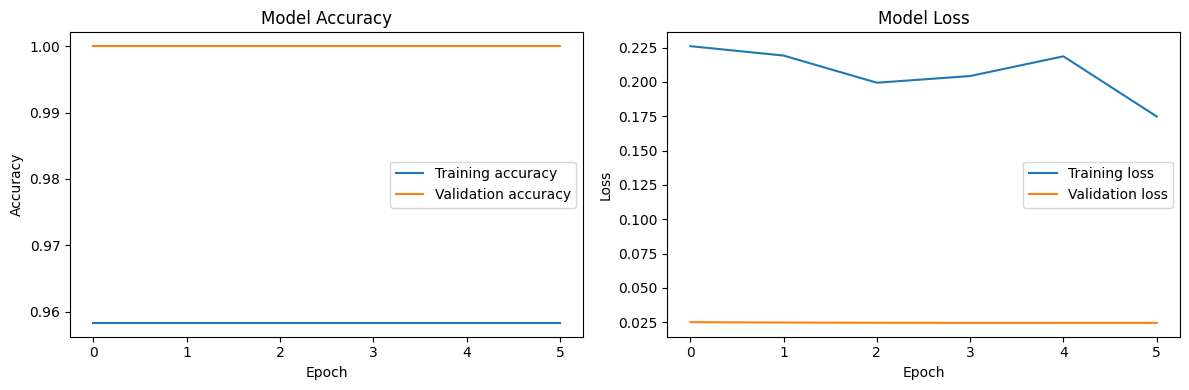

In [8]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["accuracy"], label="Training accuracy")
axes[0].plot(history.history["val_accuracy"], label="Validation accuracy")
axes[0].set_title("Model Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Training loss")
axes[1].plot(history.history["val_loss"], label="Validation loss")
axes[1].set_title("Model Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()


In [9]:

# Evaluate on the held-out test set
test_loss, test_accuracy = model.evaluate(
    test_inputs, y_test, verbose=0
)

probabilities = model.predict(test_inputs, verbose=0)
y_pred = np.argmax(probabilities, axis=1)

# Convert class indices back to 1..5 star ratings
actual_ratings = y_test + 1
predicted_ratings = y_pred + 1

accuracy = accuracy_score(actual_ratings, predicted_ratings)
precision = precision_score(
    actual_ratings, predicted_ratings,
    labels=[1, 2, 3, 4, 5],
    average="macro",
    zero_division=0
)
recall = recall_score(
    actual_ratings, predicted_ratings,
    labels=[1, 2, 3, 4, 5],
    average="macro",
    zero_division=0
)
f1 = f1_score(
    actual_ratings, predicted_ratings,
    labels=[1, 2, 3, 4, 5],
    average="macro",
    zero_division=0
)
mae = mean_absolute_error(actual_ratings, predicted_ratings)
rmse = np.sqrt(mean_squared_error(actual_ratings, predicted_ratings))

print("TEST SET EVALUATION")
print("-" * 40)
print(f"Test loss:          {test_loss:.4f}")
print(f"Accuracy:           {accuracy:.4f}")
print(f"Macro precision:    {precision:.4f}")
print(f"Macro recall:       {recall:.4f}")
print(f"Macro F1-score:     {f1:.4f}")
print(f"Mean absolute error:{mae:.4f} stars")
print(f"Root mean squared error: {rmse:.4f} stars")

print("\nClassification Report:")
print(classification_report(
    actual_ratings,
    predicted_ratings,
    labels=[1, 2, 3, 4, 5],
    zero_division=0
))


TEST SET EVALUATION
----------------------------------------
Test loss:          0.2669
Accuracy:           0.9412
Macro precision:    0.1882
Macro recall:       0.2000
Macro F1-score:     0.1939
Mean absolute error:0.0588 stars
Root mean squared error: 0.2425 stars

Classification Report:
              precision    recall  f1-score   support

           1       0.00      0.00      0.00         0
           2       0.00      0.00      0.00         0
           3       0.00      0.00      0.00         1
           4       0.94      1.00      0.97        32
           5       0.00      0.00      0.00         1

    accuracy                           0.94        34
   macro avg       0.19      0.20      0.19        34
weighted avg       0.89      0.94      0.91        34



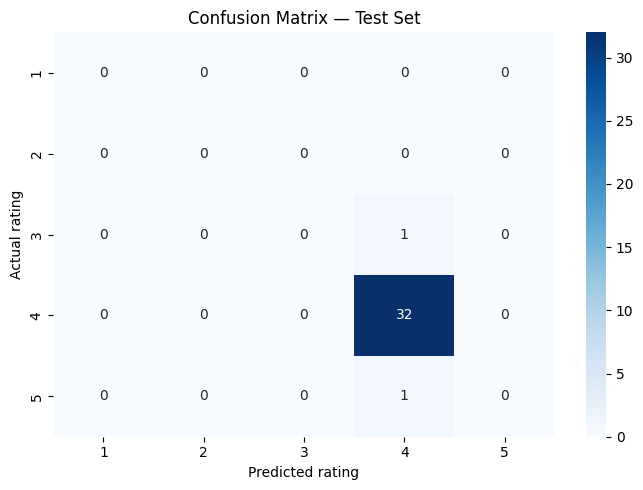

In [10]:

cm = confusion_matrix(
    actual_ratings,
    predicted_ratings,
    labels=[1, 2, 3, 4, 5]
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[1, 2, 3, 4, 5],
    yticklabels=[1, 2, 3, 4, 5]
)
plt.xlabel("Predicted rating")
plt.ylabel("Actual rating")
plt.title("Confusion Matrix — Test Set")
plt.tight_layout()
plt.show()


Actual vs Predicted Ratings:


,Review,Product,Actual Rating,Predicted Rating,Absolute Error
0,extended length for securiry camera dont judge...,EYNK Extra Long Micro USB Fast Charging USB Ca...,4,4,0
1,a well priced product lenthy cord product is w...,"Lapster 5 pin mini usb cable, usb b cable,came...",4,4,0
2,nice product and easy to use heating issues ba...,"T TOPLINE 180 W Electric Hand Mixer,Hand Blend...",4,4,0
3,ranjitha good one best one good and average us...,Noise ColorFit Pulse Grand Smart Watch with 1....,4,4,0
4,worth for the price good just average great go...,Amazon Basics 1500 W Electric Kettle (Stainles...,4,4,0
5,nice product great watch ok ok nice thik thak ...,Noise ColorFit Pro 2 Full Touch Control Smart ...,4,4,0
6,perfect egg boiler good to use worth the price...,Simxen Egg Boiler Electric Automatic Off 7 Egg...,4,4,0
7,i like the product best product with good cust...,WeCool C1 Car Mobile Holder with One Click Tec...,4,4,0
8,pack of two but only one compatible using the ...,Eureka Forbes Aquasure Amrit Twin Cartridge (P...,4,4,0
9,out of 5 iam giving 3 5 rating everything is o...,Motorola a10 Dual Sim keypad Mobile with 1750 ...,4,4,0


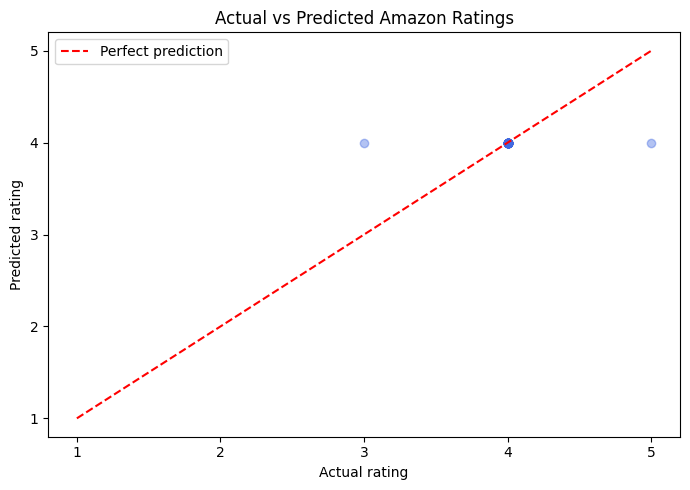

In [11]:

comparison = pd.DataFrame({
    "Review": X_test["review_text"].values,
    "Product": X_test["product_title"].values,
    "Actual Rating": actual_ratings,
    "Predicted Rating": predicted_ratings,
    "Absolute Error": np.abs(actual_ratings - predicted_ratings)
})

print("Actual vs Predicted Ratings:")
display(comparison.head(20))

# Visualize actual and predicted ratings
plt.figure(figsize=(7, 5))
plt.scatter(
    actual_ratings,
    predicted_ratings,
    alpha=0.4,
    color="royalblue"
)
plt.plot([1, 5], [1, 5], "r--", label="Perfect prediction")
plt.xticks([1, 2, 3, 4, 5])
plt.yticks([1, 2, 3, 4, 5])
plt.xlabel("Actual rating")
plt.ylabel("Predicted rating")
plt.title("Actual vs Predicted Amazon Ratings")
plt.legend()
plt.tight_layout()
plt.show()


In [12]:

def predict_rating(
    review,
    product_title="unknown product",
    category="unknown",
    product_features=None
):
    """
    Predict a 1-5 star rating for a new review.

    product_features: optional dictionary using the numeric
    column names detected during dataset preprocessing.
    Example: {"discounted_price": "₹1,299",
              "actual_price": "₹1,999"}
    """
    product_features = product_features or {}

    # Clean text using the same preprocessing function
    cleaned_review = clean_text(review)
    cleaned_title = str(product_title).strip().lower()
    if not cleaned_title:
        cleaned_title = "unknown product"

    cleaned_category = str(category).strip()
    if not cleaned_category:
        cleaned_category = "unknown"

    # Tokenize text and encode category
    review_seq = review_vectorizer(
        tf.constant([cleaned_review])
    ).numpy()

    title_seq = title_vectorizer(
        tf.constant([cleaned_title])
    ).numpy()

    category_seq = category_lookup(
        tf.constant([cleaned_category])
    ).numpy()

    # Prepare numeric features in the same order as training
    numeric_values = []

    for col in numeric_cols:
        value = product_features.get(col, medians[col])

        # Parse currency symbols, commas and percentage signs
        value = str(value).replace(",", "")
        value = re.sub(r"[₹$£%]", "", value).strip()

        try:
            value = float(value)
        except (ValueError, TypeError):
            value = float(medians[col])

        if not np.isfinite(value):
            value = float(medians[col])

        numeric_values.append(value)

    numeric_array = np.asarray(
        [numeric_values], dtype="float32"
    )
    numeric_array = scaler.transform(numeric_array).astype("float32")

    # Run model inference
    inputs = {
        "review_input": review_seq,
        "title_input": title_seq,
        "category_input": category_seq,
        "numeric_input": numeric_array
    }

    probs = model.predict(inputs, verbose=0)[0]
    predicted_star = int(np.argmax(probs)) + 1

    print("Customer review:", review)
    print("Product:", product_title)
    print("Category:", category)
    print("\nPredicted rating:", predicted_star, "out of 5")
    print("\nRating probabilities:")

    for star, probability in enumerate(probs, start=1):
        print(f"{star} star: {probability:.2%}")

    return predicted_star, probs


# Example 1: Positive review
predicted_rating_1, probabilities_1 = predict_rating(
    review="Excellent quality, works perfectly, and worth the money.",
    product_title="Wireless Bluetooth Headphones",
    category="Electronics",
    product_features={
        col: medians[col] for col in numeric_cols
    }
)

print("\n" + "=" * 50 + "\n")

# Example 2: Negative review
predicted_rating_2, probabilities_2 = predict_rating(
    review="Poor quality, stopped working after two days. Very disappointed.",
    product_title="Wireless Bluetooth Headphones",
    category="Electronics",
    product_features={
        col: medians[col] for col in numeric_cols
    }
)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


Customer review: Excellent quality, works perfectly, and worth the money.
Product: Wireless Bluetooth Headphones
Category: Electronics

Predicted rating: 4 out of 5

Rating probabilities:
1 star: 2.10%
2 star: 4.35%
3 star: 9.82%
4 star: 75.93%
5 star: 7.80%




/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


Customer review: Poor quality, stopped working after two days. Very disappointed.
Product: Wireless Bluetooth Headphones
Category: Electronics

Predicted rating: 4 out of 5

Rating probabilities:
1 star: 3.21%
2 star: 6.00%
3 star: 11.74%
4 star: 69.12%
5 star: 9.94%


In [13]:

import pickle

# Save neural network
model.save("/content/amazon_rating_model.keras")

# Save preprocessing components
preprocessing_objects = {
    "review_vectorizer": review_vectorizer,
    "title_vectorizer": title_vectorizer,
    "category_lookup": category_lookup,
    "scaler": scaler,
    "medians": medians,
    "numeric_cols": numeric_cols
}

with open("/content/amazon_preprocessing.pkl", "wb") as f:
    pickle.dump(preprocessing_objects, f)

print("Model and preprocessing objects saved.")

files.download("/content/amazon_rating_model.keras")
files.download("/content/amazon_preprocessing.pkl")


Model and preprocessing objects saved.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>